# Task 7: Generations

In [1]:
import pandas as pd

df = pd.read_json("../outputs/generations.jsonl", lines=True);
df = df.drop_duplicates(subset=["model", "prompt", "temperature", "top_k"], keep="last")

In [2]:
df.info

<bound method DataFrame.info of                   model                prompt  temperature  top_k  \
180          distilgpt2        This movie was          0.4      0   
181          distilgpt2        This movie was          0.4     10   
182          distilgpt2        This movie was          0.4     50   
183          distilgpt2        This movie was          0.4     90   
184          distilgpt2        This movie was          0.7      0   
..                  ...                   ...          ...    ...   
335  outputs/full/model  The weather today is          1.3     90   
336  outputs/full/model  The weather today is          1.6      0   
337  outputs/full/model  The weather today is          1.6     10   
338  outputs/full/model  The weather today is          1.6     50   
339  outputs/full/model  The weather today is          1.6     90   

                                                  text  distinct_1  distinct_2  
180   directed by J.J. Abrams, and directed by J.J....    

In [3]:
df.head(40)

,model,prompt,temperature,top_k,text,distinct_1,distinct_2
180,distilgpt2,This movie was,0.4,0,"directed by J.J. Abrams, and directed by J.J....",0.666667,0.750000
181,distilgpt2,This movie was,0.4,10,"directed by J.J. Abrams, and directed by J.J....",0.666667,0.750000
182,distilgpt2,This movie was,0.4,50,"directed by J.J. Abrams, and directed by J.J....",0.666667,0.750000
183,distilgpt2,This movie was,0.4,90,"directed by J.J. Abrams, and directed by J.J....",0.666667,0.750000
184,distilgpt2,This movie was,0.7,0,"designed to be a true spiritual experience, a...",0.492958,0.742857
185,distilgpt2,This movie was,0.7,10,"directed by J.J. Abrams, and it was directed ...",0.153846,0.156863
186,distilgpt2,This movie was,0.7,50,"directed by J.J. Abrams, and had been directe...",0.350000,0.406780
187,distilgpt2,This movie was,0.7,90,designed to be a true test of cinema and to s...,0.657534,0.916667
188,distilgpt2,This movie was,1.0,0,designed to be a protagonist who happens to b...,0.818182,0.953846
189,distilgpt2,This movie was,1.0,10,"directed by Mark Lichtmann, and directed by R...",0.551724,0.771930


In [4]:
df["model_short"] = df["model"].str.replace("../", "").str.replace("outputs/", "").str.replace("/model", "")

In [5]:
summary = (df.groupby(["model_short", "temperature", "top_k"])[["distinct_1", "distinct_2"]]
             .mean().round(3))
summary

distinct_1  distinct_2
model_short temperature top_k                        
distilgpt2  0.4         0           0.444       0.511
                        10          0.444       0.511
                        50          0.444       0.511
                        90          0.444       0.511
            0.7         0           0.633       0.880
                        10          0.463       0.627
                        50          0.597       0.707
                        90          0.633       0.882
            1.0         0           0.789       0.961
                        10          0.712       0.887
                        50          0.792       0.985
                        90          0.729       0.941
            1.3         0           0.921       1.000
                        10          0.820       0.963
                        50          0.806       0.989
                        90          0.823       0.993
            1.6         0           0.972       1.000
                        10          0.708       0.941
                        50          0.847       0.988
                        90          0.858       0.993
full        0.4         0           0.335       0.444
                        10          0.270       0.353
                        50          0.335       0.444
                        90          0.335       0.444
            0.7         0           0.618       0.758
                        10          0.517       0.693
                        50          0.640       0.811
                        90          0.618       0.758
            1.0         0           0.832       0.980
                        10          0.723       0.949
                        50          0.764       0.954
                        90          0.912       0.997
            1.3         0           0.944       1.000
                        10          0.743       0.967
                        50          0.865       0.992
                        90          0.825       0.997
            1.6         0           0.984       1.000
                        10          0.777       0.975
                        50          0.852       0.992
                        90          0.906       1.000

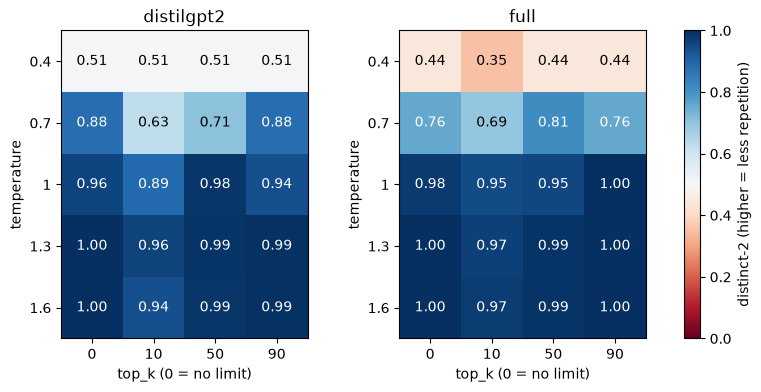

,model_short,temperature,top_k,distinct_2,text
180,distilgpt2,0.4,0,0.750000,"directed by J.J. Abrams, and directed by J.J. Abrams.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n"
181,distilgpt2,0.4,10,0.750000,"directed by J.J. Abrams, and directed by J.J. Abrams.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n"
182,distilgpt2,0.4,50,0.750000,"directed by J.J. Abrams, and directed by J.J. Abrams.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n"
183,distilgpt2,0.4,90,0.750000,"directed by J.J. Abrams, and directed by J.J. Abrams.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n"
184,distilgpt2,0.7,0,0.742857,"designed to be a true spiritual experience, and had the blessing of a wonderful God.\nA series of religious episodes were produced by the Turner Broadcasting Company for the television series. The series also contains a number of original episodes of The Simpsons, The Simpsons, and The Simpsons.\nThe original series was produced by Turner Broadcasting Company for the television series. The series also contains a number of original episodes of"
185,distilgpt2,0.7,10,0.156863,"directed by J.J. Abrams, and it was directed by J.J. Abrams, and it was directed by J.J. Abrams, and it was directed by J.J. Abrams, and it was directed by J.J. Abrams, and it was directed by J.J. Abrams, and it was directed by J.J. Abrams, and it was directed by J"
186,distilgpt2,0.7,50,0.406780,"directed by J.J. Abrams, and had been directed by Christopher Nolan. The film was directed by Mark Hamill (The New York Times), and had been directed by Mark Hamill (The New York Times), and had been directed by Mark Hamill (The New York Times), and had been directed by Mark Hamill (The New York Times).\n\n\n\nThe film was originally released"
187,distilgpt2,0.7,90,0.916667,"designed to be a true test of cinema and to show the true nature of cinema and not just how serious the film was (but also how far and away it could be), but how much it takes to convince the audience of what is happening here.\nThe movie is about the evolution of the cinema, the evolution of the cinema.\nWe will see further episodes of the movie later in the year"
188,distilgpt2,1.0,0,0.953846,designed to be a protagonist who happens to be a character who seeks revenge on his father who committed treason against the Crown Continent (which will always be done for him in such a way that it would be a *few* stop at all times) but he is very much an unwary player.Things are worse when Tyria's Kimville and Scotland's Rossuson are caught in a nefarious
189,distilgpt2,1.0,10,0.771930,"directed by Mark Lichtmann, and directed by Robert C. Brown (The Dark Knight).\n\n\n\n\nThe film will release on September 27th in the United States and on DVD in the United Kingdom and on Blu-Ray and DVD on May 27th in the United States and on DVD. The film will be produced by John Wigel, John Wigel, and David"


In [6]:
import matplotlib.pyplot as plt

df["temperature"] = df["temperature"].round(2)

models = df["model_short"].unique()
fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 4), squeeze=False)
for ax, m in zip(axes[0], models):
    pivot = df[df["model_short"] == m].pivot_table(index="temperature", columns="top_k",
                                                    values="distinct_2", aggfunc="mean")
    im = ax.imshow(pivot, cmap="RdBu", vmin=0, vmax=1)   # red = repetitive, blue = diverse
    ax.set_xticks(range(len(pivot.columns)), [f"{c:g}" for c in pivot.columns])
    ax.set_yticks(range(len(pivot.index)), [f"{t:g}" for t in pivot.index])
    ax.set_xlabel("top_k (0 = no limit)"); ax.set_ylabel("temperature"); ax.set_title(m)
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            v = pivot.iloc[i, j]
            # white text on the saturated ends, black on the pale middle
            ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                    color="white" if abs(v - 0.5) > 0.25 else "black")
fig.colorbar(im, ax=axes, label="distinct-2 (higher = less repetition)")
plt.show()

# Read the actual texts for one prompt across settings (for the qualitative part)
pd.set_option("display.max_colwidth", None)
df[df["prompt"] == "This movie was"][["model_short", "temperature", "top_k", "distinct_2", "text"]]